# Compose, inspect and run peptide optimization in Python

pep-compass is a tool for constructing peptide optimization algorithms. The
`Pipeline` wrapper provides access to registered components, builds their
computational graph and executes it through one runner.

Main library concept is to separate:
- **declarations** - (`PipelineSchema`) provides editable algorithm configuration,
- **executable Step tree** - is constructed by `build()` from those declarations,

> Functionality is separated in single methods 

The examples use CPU, the bundled HydrAMP `article_25` weights and a local
hydrophobicity oracle. The short LE-BO example substitutes this inexpensive oracle
for APEX and explicitly reduces its search bounds; it is a usage demonstration,
not a reproduction of publication results. All calculations call library APIs.

In [1]:
from dataclasses import replace
from pathlib import Path
# Remark: this import is to avoid local saving 
from tempfile import mkdtemp

import pandas as pd
from IPython.display import display

from pep_compass import Pipeline, Step, Loop, Parallel, LocalEnumeration
from pep_compass.optimization.saving import AnalysisReader

SEED = 7
SEQUENCES = ["FLYKWWIRIGRLKL"]
AUTOENCODER_PARAMETERS = {"jacobian_mode": "approx"}

## Search implemented methods

To avoid looking through library and provide convenient way to access documentation, we provide methods for lookup.
- `describe()` - provides all implemented  components 
- `describe_component` - provides extended documentation of given element

In [2]:
pipeline = Pipeline()
# USAGE: The default mode displays a formatted catalog automatically. (table you see) 
# REMARK: plotted results 
pipeline.describe()  

# USAGE: Request a return value only when further Python processing is needed.
choices_pd = pipeline.describe(display="pd")     # pandas.DataFrame
choices_raw = pipeline.describe(display="raw")   # original list of dictionaries
assert len(choices_pd) == len(choices_raw)

/home/max/repositories/pep-compass/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


component,strategy,description,internal_stages
filter,candidate_subset,Select at most a fixed number of candidates from the complete batch.,
filter,deduplicate,Keep the first candidate for every configured identity key.,
filter,esm_plausibility,Build ESM scoring with exactly one threshold or top-k rule.,
filter,lams,Build the LAMS mutation-choice filter.,
filter,levenshtein,Keep sequences within an inclusive edit radius of a reference.,
filter,lpbebo,Build the LPBEBO mutation-choice filter.,
filter,move,Build the MOVE mutation-choice filter.,
filter,random_mutang,Build random MUTANG-mode mutation selection.,
filter,random_walker,Build random walker-mode mutation selection.,
filter,ranked,Build an explicit score-and-selection filter composition.,"scoring, selection"


In [3]:
# USAGE: Restrict the catalog to a family,
pipeline.describe(component="filter")

component,strategy,description,internal_stages
filter,candidate_subset,Select at most a fixed number of candidates from the complete batch.,
filter,deduplicate,Keep the first candidate for every configured identity key.,
filter,esm_plausibility,Build ESM scoring with exactly one threshold or top-k rule.,
filter,lams,Build the LAMS mutation-choice filter.,
filter,levenshtein,Keep sequences within an inclusive edit radius of a reference.,
filter,lpbebo,Build the LPBEBO mutation-choice filter.,
filter,move,Build the MOVE mutation-choice filter.,
filter,random_mutang,Build random MUTANG-mode mutation selection.,
filter,random_walker,Build random walker-mode mutation selection.,
filter,ranked,Build an explicit score-and-selection filter composition.,"scoring, selection"


In [4]:
# USAGE: inspect one exact strategy.
pipeline.describe_component(component="filter", strategy="candidate_subset")


In [5]:
# REMARK: Internal strategies are grouped into expandable sections.
pipeline.describe_component(component="walker", strategy="sorbes")
pipeline.describe_component(component="autoencoder", strategy="hydramp")

# REMARK: describe_step remains a compatible alias. New examples use component.
walker_parameters = pipeline.describe_component("walker", "sorbes", display="pd")
assert walker_parameters["section"].str.startswith("internal.").any()


## Construct a pipeline: three equivalent styles

The autoencoder is a shared resource configured by `add_autoencoder()`. It is loaded at `build()` and used by computational components. 

We use following attributes: 
- *position*, such as `0.walker.0` or `0.filters.0`, describes the **current place** in the declaration tree. 
- *node_id* identifies **the same node across edits** and execution records. 

> Important here is that:
> - *positions* can move; 
> - *node_IDs* remain stable. 

Build resolves defaults, validates field dependencies and constructs components. **It does not run the optimization**. The graph structure and IDs stay the same across that build.


Firstly we examine how to build graph from scratch

Each of the next three cells creates the same small algorithm: 
- private local trajectories generate mutations, 
- duplicate candidates are removed,
- at most three candidates are chosen for hydrophobicity evaluation, 
- completed evaluations are retained.

Each style displays its graph before and after `build()`. 

Style 1 — before build


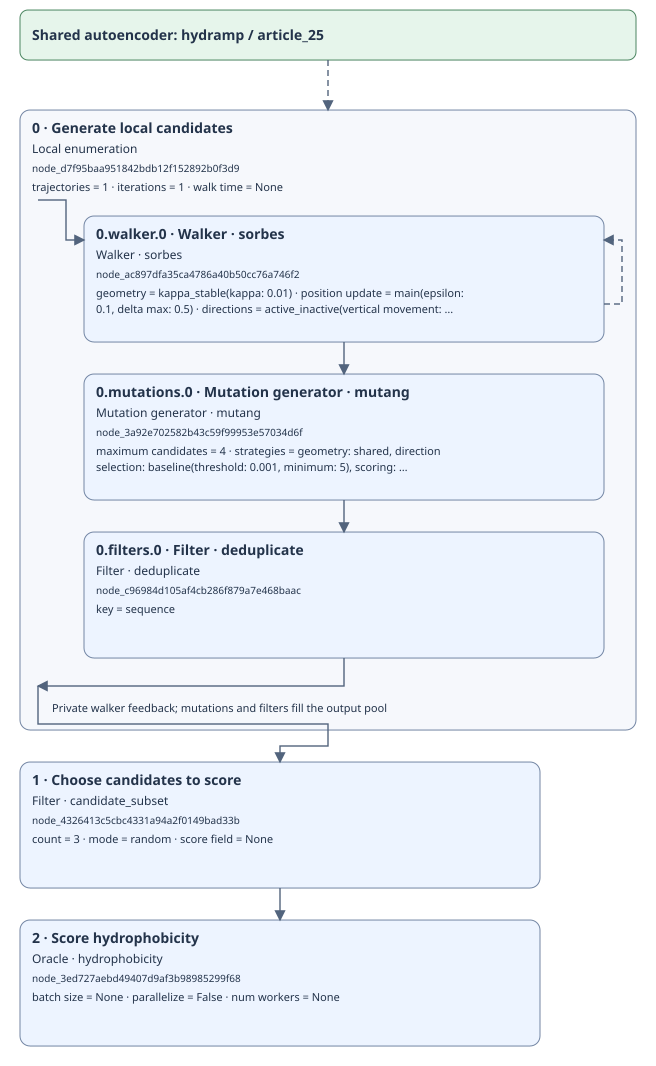

Style 1 — after build


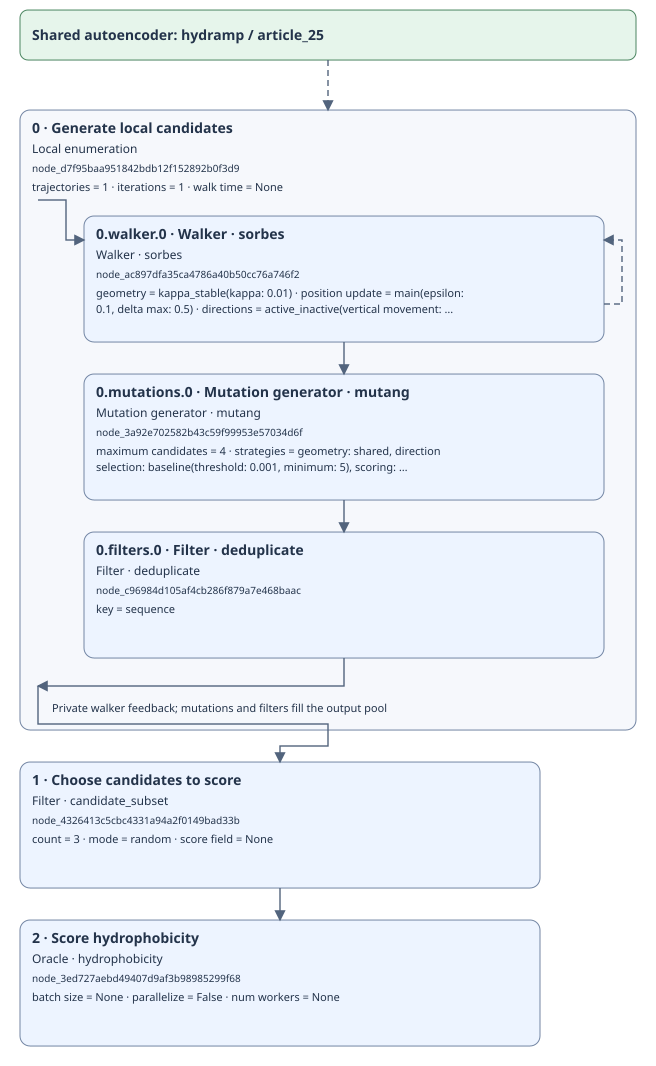

In [6]:
# USAGE: Style 1 — add components incrementally.
## Create object 
incremental = Pipeline()
## Add general settings
incremental.add_autoencoder(strategy="hydramp", model="article_25", device="cpu", parameters=AUTOENCODER_PARAMETERS)
## Add step 0 
incremental.add_local_enumeration(
    name="Generate local candidates", trajectories=1, iterations=1,
    include_walk_points=False,
    ## *Manually* add steps to local enumeration
    walker=Step.create(component="walker", strategy="sorbes", parameters={"time_step": 0.01}),
    mutation_generator=Step.create(component="mutation_generator", strategy="mutang", parameters={"maximum_candidates": 4}),
    filters=[Step.create(component="filter", strategy="deduplicate")],
)
## Add step 1 - select three candidates
incremental.add_component("filter", "candidate_subset", name="Choose candidates to score", parameters={"count": 3})
## Add step 2 - oracle evaluation
oracle_node = incremental.add_component("oracle", "hydrophobicity", name="Score hydrophobicity")

print("Style 1 — before build")
display(incremental.show())
incremental.build(execution={"seed": SEED})
print("Style 1 — after build")
display(incremental.show())
pipeline = incremental


Style 2 — before build


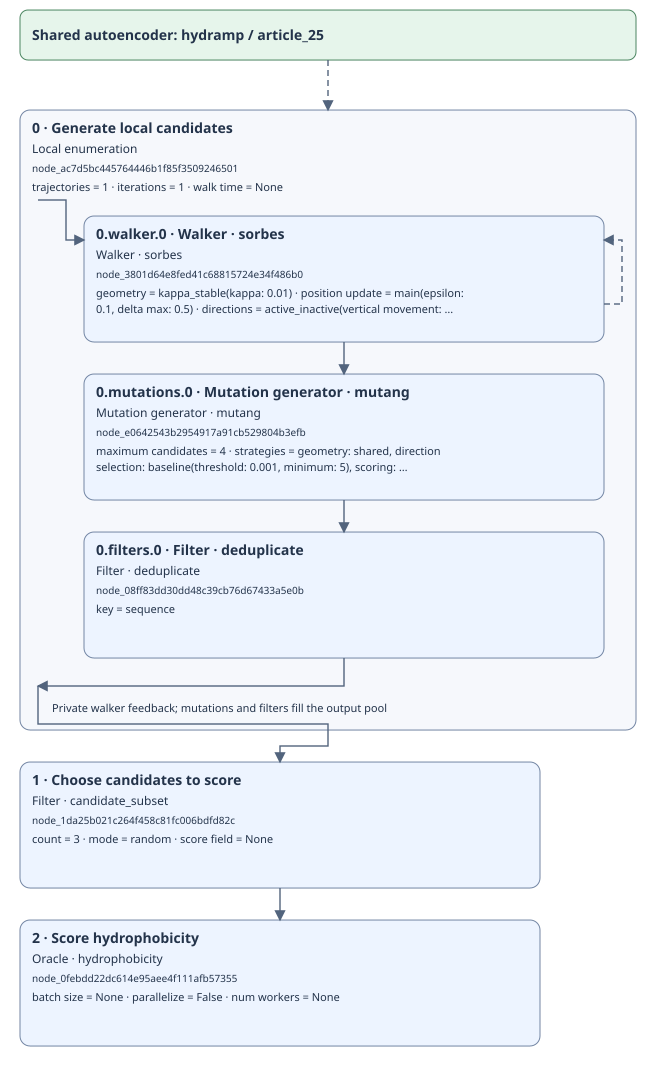

Style 2 — after build


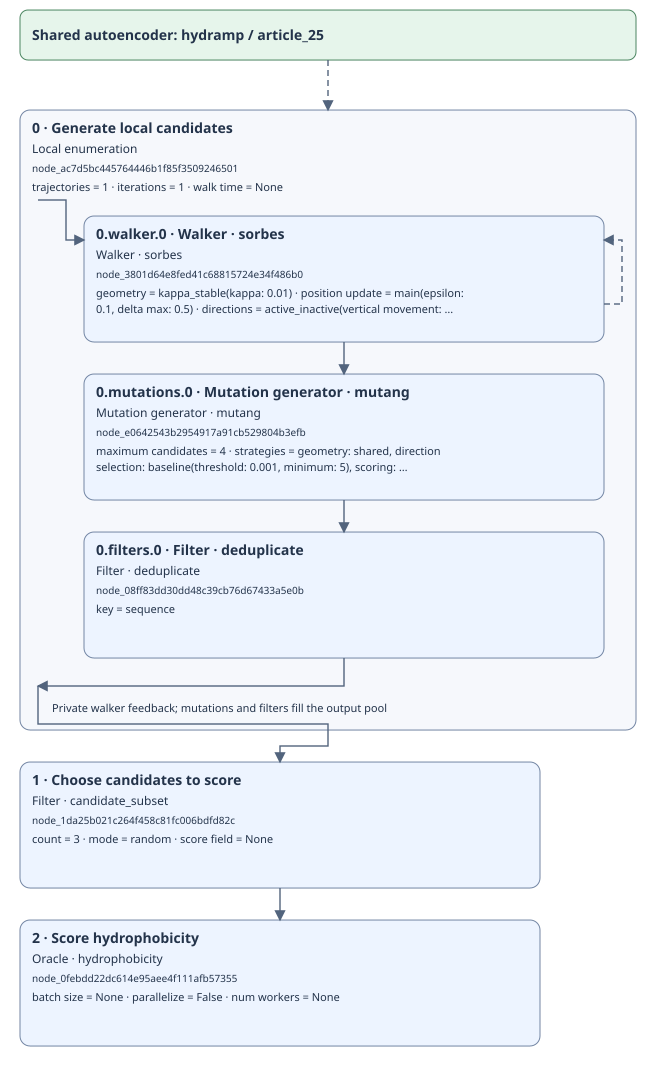

In [7]:
# USAGE: Style 2 — construct declarations separately, then assemble them.
## Declare all objects (they are **not** constructed) 
### Create step 0 - local enumeration block 
walker = Step.create(component="walker", strategy="sorbes", parameters={"time_step": 0.01})
mutations = Step.create(component="mutation_generator", strategy="mutang", parameters={"maximum_candidates": 4})
unique = Step.create(component="filter", strategy="deduplicate")
local = LocalEnumeration.create(
    name="Generate local candidates", walker=walker, mutation_generator=mutations,
    filters=[unique], trajectories=1, iterations=1, include_walk_points=False,
)
### Create step 1 - select three candidates
selection = Step.create(component="filter", strategy="candidate_subset", name="Choose candidates to score", parameters={"count": 3})

### Create step 2 - oracle evaluation
scoring = Step.create(component="oracle", strategy="hydrophobicity", name="Score hydrophobicity")

## Define loop: 
separate = Pipeline.create(steps=[
    local,      ### Add step 0
    selection,  ### Add step 1
    scoring     ### Add step 2    
])
### Add general setings
separate.add_autoencoder(parameters=AUTOENCODER_PARAMETERS)

print("Style 2 — before build")
display(separate.show())
separate.build(execution={"seed": SEED})
print("Style 2 — after build")
display(separate.show())


Style 3 — before build


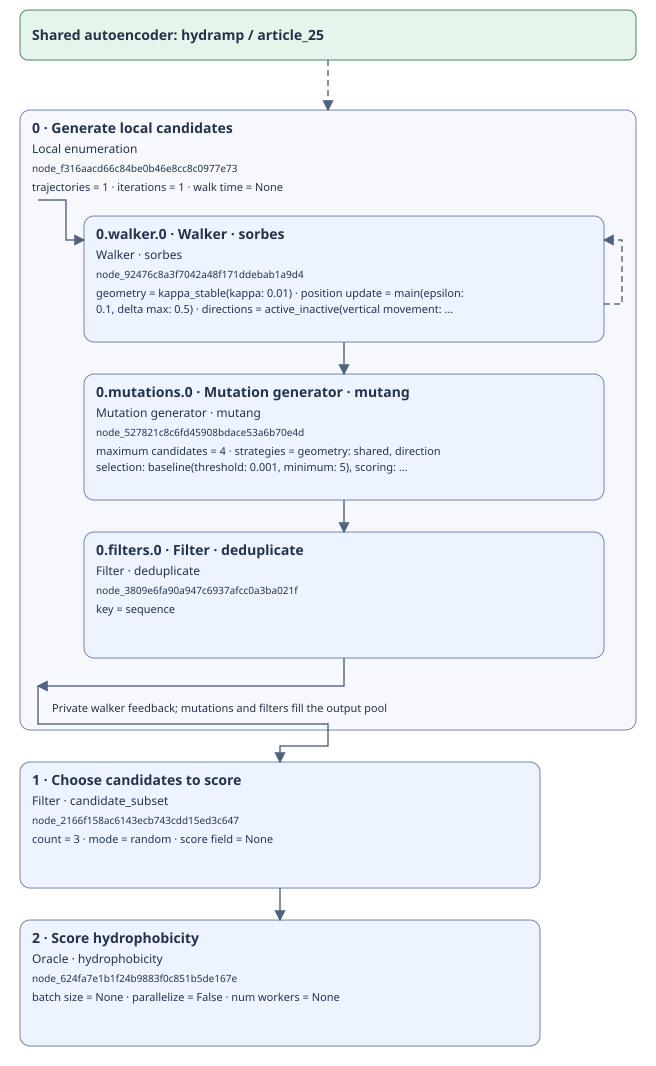

Style 3 — after build


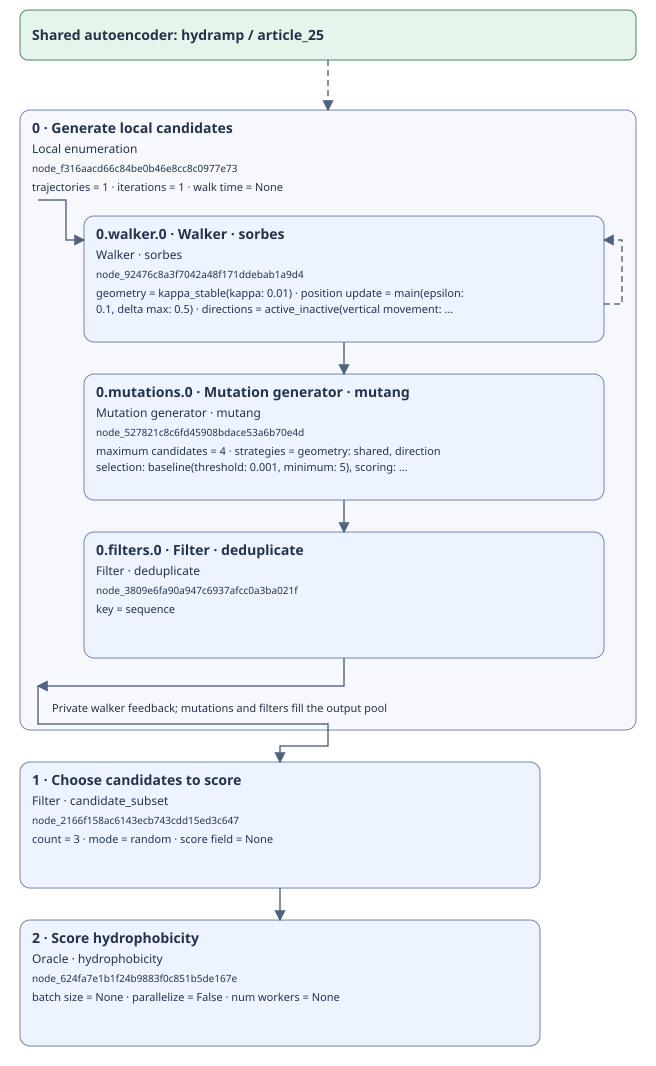

In [8]:
# USAGE: Style 3 — declare the same graph directly inside Pipeline.create.
inline = Pipeline.create(steps=[
    ## Add step 0 
    LocalEnumeration.create(
        name="Generate local candidates", trajectories=1, iterations=1, include_walk_points=False,
        walker=Step.create(component="walker", strategy="sorbes", parameters={"time_step": 0.01}),
        mutation_generator=Step.create(component="mutation_generator", strategy="mutang", parameters={"maximum_candidates": 4}),
        filters=[Step.create(component="filter", strategy="deduplicate")],
    ),
    ## Add step 1
    Step.create(component="filter", strategy="candidate_subset", name="Choose candidates to score", parameters={"count": 3}),
    ## Add step 2 
    Step.create(component="oracle", strategy="hydrophobicity", name="Score hydrophobicity"),
])
inline.add_autoencoder(parameters=AUTOENCODER_PARAMETERS)

print("Style 3 — before build")
display(inline.show()) 
inline.build(execution={"seed": SEED})
print("Style 3 — after build")
display(inline.show())


Now we examine how to modify *existing* PipelineSchema - class which is stored inside `Pipeline`. 

Before edits


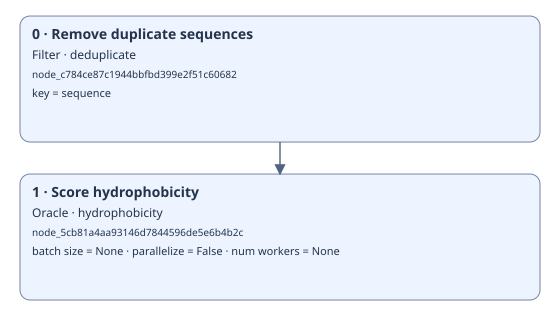

After insertion and replacement; replacement retained the first identity


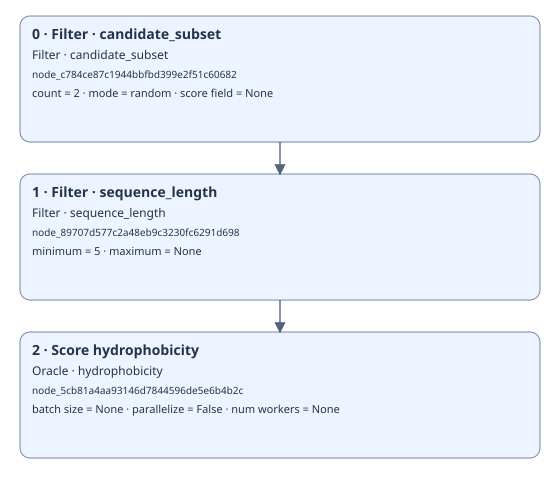

name,value
node_id,node_5cb81a4aa93146d7844596de5e6b4b2c
name,Score hydrophobicity
position,2
parent_id,None
previous_id,node_89707d577c2a48eb9c3230fc6291d698
next_id,None
name,value
component,oracle
strategy,hydrophobicity
description,Build the hydrophobicity oracle strategy.


After removing the inserted length rule


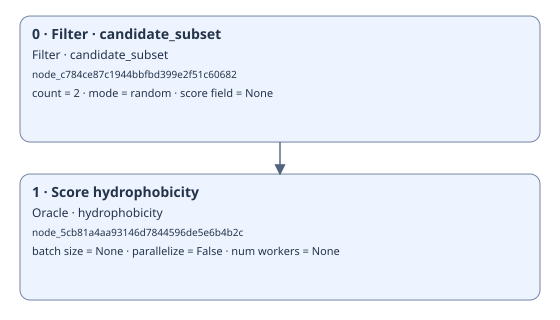

In [9]:
# USAGE: Edit a small declaration graph before building it.
## Create Pipeline object
draft = Pipeline()
### Those objects contain their ides 
first = draft.add_component("filter", "deduplicate", name="Remove duplicate sequences")
scoring = draft.add_component("oracle", "hydrophobicity", name="Score hydrophobicity")
print("Before edits")
display(draft.show())

## Insert or replace new element
length_rule = Step.create(component="filter", strategy="sequence_length", parameters={"minimum": 5})
### it takes `length_rule` and place before scoring
### function new where to place it based on **node_id** - it is important, because step is not recognized
draft.insert_step(length_rule, before=scoring.node_id)
### replace step: 
draft.replace_step(first.node_id, 
    Step.create(
        component="filter", 
        strategy="candidate_subset", 
        parameters={"count": 2})
    )
assert draft.to_schema().steps[0].node_id == first.node_id
print("After insertion and replacement; replacement retained the first identity")
display(draft.show())
draft.describe_component(node_id=scoring.node_id)

draft.remove_step(length_rule.node_id)
print("After removing the inserted length rule")
display(draft.show())


### Schema and graph formats

<!-- #TODO - note validated -->

`to_schema()` returns a configuration object. `to_schema("json")` serializes that
configuration for programs; it contains no model weights or run results.
`to_schema("text")` is a textual structure report. `to_schema("mermaid")` produces
**Mermaid source text**, for a Markdown/Mermaid renderer. `show()` or
`show("svg")` produces a ready-to-display vector image in Jupyter. Mermaid and SVG
describe the same algorithm, but only the SVG is already a rendered image.

Solid graph arrows follow candidate flow. Entering a nested body points right;
returning to its parent points left. Dashed feedback returns to the first loop
step or the private walker, as appropriate. The shared-model connection is a
resource relationship, not an extra optimization step.

In [10]:
print("Readable schema report:")
print(draft.to_schema("text"))
print("Mermaid source — paste into a Mermaid renderer:")
print(draft.to_schema("mermaid"))
print("JSON declaration:")
print(draft.to_schema("json"))


Readable schema report:
0 [node_c784ce87c1944bbfbd399e2f51c60682] filter: candidate_subset: {"count":2,"mode":"random","score_field":null} parent=root
1 [node_5cb81a4aa93146d7844596de5e6b4b2c] Score hydrophobicity: {"batch_size":null,"parallelize":false,"num_workers":null} parent=root
Mermaid source — paste into a Mermaid renderer:
flowchart TD
  n0["0 · Filter · candidate_subset | Filter · candidate_subset | node_c784ce87c1944bbfbd399e2f51c60682 | {&quot;count&quot;:2,&quot;mode&quot;:&quot;random&quot;,&quot;score_field&quot;:null}"]
  n1["1 · Score hydrophobicity | Oracle · hydrophobicity | node_5cb81a4aa93146d7844596de5e6b4b2c | {&quot;batch_size&quot;:null,&quot;parallelize&quot;:false,&quot;num_workers&quot;:null}"]
  n0 --> n1
JSON declaration:
{
  "version": 1,
  "autoencoder": null,
  "steps": [
    {
      "node_id": "node_c784ce87c1944bbfbd399e2f51c60682",
      "name": null,
      "type": "step",
      "component": "filter",
      "strategy": "candidate_subset",
      "para

## Runner: execution, monitoring data and result selection

The runner executes one built graph. Algorithm structure (loop counts, local
trajectory bounds and component parameters) belongs to the graph. Execution
seeds, device and soft evaluation/generation budgets belong to `execution`.
The seed covers automatic component construction and execution. Complete batches
may cross a soft budget; completed evaluations are kept.

The three following cells set the three independent groups. `storage` selects
which progress and reconstruction information is retained, along with its
backend; it does not change the algorithm or create a separate live dashboard.
`results` selects the returned object. `run()` finalizes the current buffer and
records success/failure automatically. Per-run overrides leave configured defaults
unchanged. These are the actual library defaults before the tutorial overrides:

In [11]:
# USAGE: Inspect defaults directly, so this table follows the installed API.
default_settings = Pipeline().runner_settings.to_dict()
display(pd.json_normalize(default_settings, sep=".").T.rename(columns={0: "Library default"}))

execution_options = {
    "seed": SEED,                 # USAGE: reproducible construction and execution. Default: None.
    "device": "cpu",              # USAGE: shared resource device; rebuild if changed. Default: None (resource declaration).
    "oracle_calls": 3,            # USAGE: evaluated-sequence threshold, not Python calls. Default: None (unlimited).
    "generated_candidates": 32,   # USAGE: generated-candidate threshold. Default: None (unlimited).
    "max_workers": 1,             # REMARK: only 1 is supported for this single-graph runner. Default: 1.
}
pipeline.set_runner_settings(execution=execution_options)


,Library default
execution.seed,None
execution.device,None
execution.oracle_calls,None
execution.generated_candidates,None
execution.max_workers,1
storage.backend,memory
storage.path,None
storage.profile,base
storage.flush_every,1
storage.reconstruction,none


In [12]:
monitoring_options = {
    "profile": "base",                 # REMARK: only base is currently supported. Default: "base".
    "flush_every": 10,                  # USAGE: commit every N operator-iteration events. Default: 1; final remainder always committed.
    "reconstruction": "boundaries",     # USAGE: none / boundaries / trajectories. Default: "none"; trajectories also saves walker points.
    "component_data": "summary",        # USAGE: none / summary / full output fields. Default: "none".
    "save_observation_history": True,   # USAGE: retain every repeated evaluation. Default: False.
    "save_lineage": True,               # USAGE: retain candidate provenance identifiers. Default: False.
    "save_terminal": True,              # USAGE: retain the exact batch leaving the graph. Default: False.
}
pipeline.set_runner_settings(storage=monitoring_options)
# REMARK: base always keeps the latest evaluation of every objective/sequence,
# including candidates discarded later; it is distinct from the terminal batch.


In [13]:
pipeline.set_runner_settings(
    storage={
        "backend": "memory",  # USAGE: memory or sqlite. Default: "memory"; both have the same logical schema.
        "path": None,         # USAGE: new run directory for sqlite; must be None for memory. Default: None.
    },
    results={
        "return_mode": "result",  # USAGE: result / reader / path. Default: "result"; path requires sqlite.
    },
)
# REMARK: result gives summary, reader and save(); reader returns the same reader
# directly; path returns a completed SQLite bundle directory.
result = pipeline.run(sequences=SEQUENCES)


display(result.archive[["objective", "sequence", "score", "direction"]])
display(pd.DataFrame([result.summary]))
print("Terminal sequences:", result.reader.get_final_batch().sequences)


,objective,sequence,score,direction
0,hydrophobicity,FLYKWWFRIGRLWL,0.269286,maximize
1,hydrophobicity,FLYKWWIRIGRLKL,0.118571,maximize
2,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize


,status,duration_seconds,oracle_calls,generated_candidates,completed_iterations,iteration_events,best_sequence,best_score,objective_name,terminal_count,error
0,completed,1.171733,3,4,1,1,FLYKWWIRIGRLWL,0.283571,hydrophobicity,3,None


Terminal sequences: ('FLYKWWFRIGRLWL', 'FLYKWWIRIGRLKL', 'FLYKWWIRIGRLWL')


### A short LE-BO run

The preset has a loop with local enumeration, sequence constraints, deduplication,
a trust region, Bayesian ROBOT candidate selection, an oracle and trust-region
updates. Here it runs just two iterations with two trajectories, eight mutation
candidates per local generation and a soft budget of four evaluated peptides.
ROBOT starts from seeded selection and fits its surrogate once observations exist.
Hydrophobicity replaces APEX consistently in selection, evaluation and updates;
no APEX weights or service are needed for this tutorial.

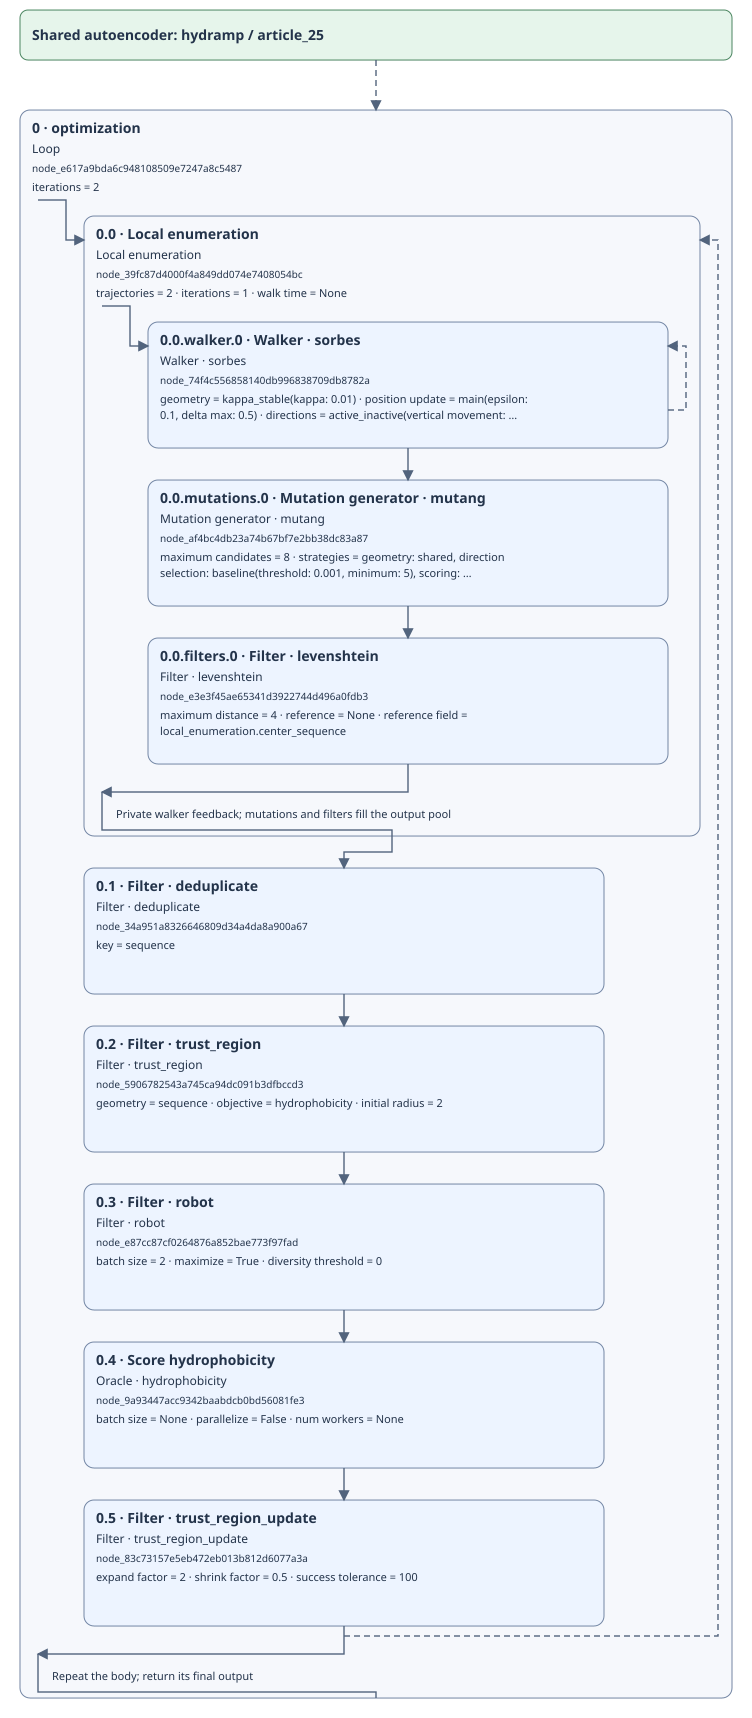

,objective,sequence,score
0,hydrophobicity,FLYKWWIRPGRLWL,0.192143
1,hydrophobicity,FLYKWWHRPGRLKL,-0.101429
2,hydrophobicity,FLYKWWFRIGRLWL,0.269286
3,hydrophobicity,FLYKWWIRIGRLKL,0.118571


,status,duration_seconds,oracle_calls,generated_candidates,completed_iterations,iteration_events,best_sequence,best_score,objective_name,terminal_count,error
0,completed,0.559699,4,48,8,4,FLYKWWFRIGRLWL,0.269286,hydrophobicity,2,None


In [14]:
# USAGE: Start from the real preset, then edit the existing node identities.
lebo = Pipeline.from_predefined('lebo', device='cpu', seed=SEED, mutation_candidates=8, oracle_calls=4)
root = lebo.to_schema().steps[0]
lebo.replace_step(root.node_id, replace(root, iterations=2))
local = root.steps[0]
lebo.replace_step(local.node_id, replace(local, trajectories=2, iterations=1, walk_time=None))
for node in root.steps[1:]:
    if node.component == 'oracle':
        replacement = Step.create(component='oracle', strategy='hydrophobicity', name='Score hydrophobicity')
    elif node.strategy in {'trust_region','robot','trust_region_update'}:
        parameters = {**dict(node.parameters), 'objective':'hydrophobicity'}
        if node.strategy in {'robot','trust_region_update'}:
            parameters['maximize'] = True
        if node.strategy == 'robot':
            parameters.update(batch_size=2,diversity_threshold=0)
        replacement = Step.create(component='filter', strategy=node.strategy, parameters=parameters)
    else:
        continue
    lebo.replace_step(node.node_id,replacement)
lebo.set_runner_settings(storage={'save_terminal':True})
lebo.build()
display(lebo.show())
lebo_result = lebo.run(SEQUENCES)
display(lebo_result.archive[["objective", "sequence", "score"]])
display(pd.DataFrame([lebo_result.summary]))
assert lebo_result.summary["oracle_calls"] <= 4


### Save run data and export graph formats

The canonical run format is a directory with **settings.json + results.sqlite**.
The memory backend uses the same relational schema and can be exported with
`result.save(path)`. A SQLite run writes that format directly. JSON records
resolved graph/settings/inputs and model/code identity; SQLite holds evaluated
peptides, progress and enabled optional categories. Tensor payloads preserve dtype,
shape and masks. Weights are referenced rather than copied.

Graph exports (`.json`, `.txt`, `.mmd`, `.svg`) describe the algorithm; they are
not interchangeable with a saved run. CSV is an optional export of an explicitly
selected analysis table, not a complete run/checkpoint format.

In [15]:
artifacts = Path(mkdtemp(prefix="pep-compass-wrapper-"))
run_directory = artifacts / "sqlite_run"
stored = pipeline.run(
    sequences=SEQUENCES,
    storage={"backend": "sqlite", "path": str(run_directory)},
    results={"return_mode": "result"},
)
assert {path.name for path in run_directory.iterdir()} == {"settings.json", "results.sqlite"}
result.save(artifacts / "memory_export")

pipeline.save_schema(artifacts / "pipeline.schema.json")
for format, filename in (("text", "pipeline.txt"), ("mermaid", "pipeline.mmd"), ("svg", "pipeline.svg")):
    (artifacts / filename).write_text(pipeline.to_schema(format), encoding="utf-8")
print("Saved artifacts:", artifacts)
# REMARK: The per-run SQLite override did not change pipeline defaults.
assert pipeline.runner_settings.storage.backend == "memory"


Saved artifacts: /tmp/pep-compass-wrapper-mmpop6ds


In [16]:
# USAGE: The other return modes change the returned view, not the computation.
reader_only = separate.run(SEQUENCES, seed=SEED, results={"return_mode": "reader"})
display(reader_only.get_archive()[["objective", "sequence", "score"]])
reader_only.close()

completed_path = inline.run(
    SEQUENCES, seed=SEED,
    storage={"backend": "sqlite", "path": str(artifacts / "path_return")},
    results={"return_mode": "path"},
)
print("Completed bundle directory:", completed_path)


,objective,sequence,score
0,hydrophobicity,FLYKWWFRIGRLWL,0.269286
1,hydrophobicity,FLYKWWIRIGRLKL,0.118571
2,hydrophobicity,FLYKWWIRIGRLWL,0.283571


Completed bundle directory: /tmp/pep-compass-wrapper-mmpop6ds/path_return


## Analysis through one reader contract

`AnalysisReader` exposes the same logical tables for memory, exported memory and
SQLite runs. This keeps writing, reading and analysis consistent: downstream
code consumes canonical columns instead of implementing a second interpretation
of saved files. Construction is lazy; `tables[name].scan(columns, chunk_size=...)`
loads bounded chunks. `get_archive()` explicitly materializes the latest scores;
`get_best_candidate(objective=...)` selects one objective.

History, lineage, terminal batches and component records are available only if
requested before execution; otherwise their access raises `DataUnavailableError`.
`get_metadata()` combines the resolved manifest and run summary. Opening or
inspecting a reader runs no model. `reconstruct_local_enumeration(checkpoint_id)`
explicitly rebuilds one saved boundary with its batch, RNGs and computational
state. It returns a digest verdict for ordered sequence content and count;
general interrupted-run continuation is a different capability.

In [17]:
reopened = AnalysisReader(run_directory)
archive = reopened.get_archive(objective="hydrophobicity")
display(archive[["sequence", "score", "evaluation_index", "first_evaluation_index"]])
display(pd.DataFrame([reopened.get_best_candidate(objective="hydrophobicity")]))
display(reopened.get_history())
display(reopened.get_lineage()[["sequence", "lineage"]])
display(reopened.get_component_data()[["node_id", "name", "data"]])
print("Recorded retention:", reopened.get_metadata()["settings"]["runner_settings"]["storage"])

for chunk in reopened.tables["iterations"].scan(
    ["node_id", "iteration_index", "duration_seconds", "interval_seconds"], chunk_size=2
):
    display(chunk)
archive.to_csv(artifacts / "evaluated_peptides.csv", index=False)

# USAGE: Compare the same logical table after exporting the memory run.
exported = AnalysisReader(artifacts / "memory_export")
pd.testing.assert_frame_equal(exported.get_archive(), reopened.get_archive())


,sequence,score,evaluation_index,first_evaluation_index
0,FLYKWWFRIGRLWL,0.269286,0,0
1,FLYKWWIRIGRLKL,0.118571,1,1
2,FLYKWWIRIGRLWL,0.283571,2,2


,objective,sequence,score,direction,evaluation_index,first_evaluation_index,lineage_json
0,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,2,2,"{""lineage.candidate_id"": 5, ""lineage.parent_ca..."


,observation_id,objective,sequence,score,direction,lineage_json
0,1,hydrophobicity,FLYKWWFRIGRLWL,0.269286,maximize,"{""lineage.candidate_id"": 3, ""lineage.parent_ca..."
1,2,hydrophobicity,FLYKWWIRIGRLKL,0.118571,maximize,"{""lineage.candidate_id"": 4, ""lineage.parent_ca..."
2,3,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,"{""lineage.candidate_id"": 5, ""lineage.parent_ca..."


,sequence,lineage
0,FLYKWWFRIGRLWL,"{'lineage.candidate_id': 3, 'lineage.parent_ca..."
1,FLYKWWIRIGRLKL,"{'lineage.candidate_id': 4, 'lineage.parent_ca..."
2,FLYKWWIRIGRLWL,"{'lineage.candidate_id': 5, 'lineage.parent_ca..."


,node_id,name,data
0,node_ac897dfa35ca4786a40b50cc76a746f2,SorbesWalker,"{'geometry': {'method': 'kappa_stable', 'param..."
1,node_3a92e702582b43c59f99953e57034d6f,MutangGenerator,"{'maximum_candidates': 4, 'strategies': {'geom..."
2,node_c96984d105af4cb286f879a7e468baac,DeduplicateFilter,{'key': 'sequence'}
3,node_d7f95baa951842bdb12f152892b0f3d9,Flow,{}
4,node_d7f95baa951842bdb12f152892b0f3d9,Generate local candidates,{}
5,node_4326413c5cbc4331a94a2f0149bad33b,Choose candidates to score,"{'count': 3, 'mode': 'random', 'score_field': ..."
6,node_3ed727aebd49407d9af3b98985299f68,Score hydrophobicity,{}
7,None,Flow,{}


Recorded retention: {'backend': 'sqlite', 'component_data': 'summary', 'flush_every': 10, 'path': '/tmp/pep-compass-wrapper-mmpop6ds/sqlite_run', 'profile': 'base', 'reconstruction': 'boundaries', 'save_lineage': True, 'save_observation_history': True, 'save_terminal': True}


,node_id,iteration_index,duration_seconds,interval_seconds
0,node_d7f95baa951842bdb12f152892b0f3d9,0,0.041935,None


In [18]:
checkpoints = pd.concat(reopened.tables["checkpoints"].scan(
    ["checkpoint_id", "node_id", "execution_id"]
), ignore_index=True)
display(checkpoints)
replay = reopened.reconstruct_local_enumeration(int(checkpoints.iloc[0]["checkpoint_id"]))
assert replay.matches
print("Replay matches:", replay.matches, "candidates:", len(replay.candidates))

# USAGE: Close readers/results after all reads; persisted bundles remain on disk.
exported.close()
reopened.close()
stored.close()
result.close()
lebo_result.close()
# REMARK: return_mode='path' keeps the wrapper's last result available for inspection.
inline.last_result.close()


,checkpoint_id,node_id,execution_id
0,1,node_d7f95baa951842bdb12f152892b0f3d9,5


Replay matches: True candidates: 4
